# Fine-Tunning Bert For sentiment classification

## Importing Libraries


In [46]:

from transformers import  AutoTokenizer, BertForSequenceClassification , DataCollatorWithPadding
import torch 
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import pandas as pd
from tqdm import tqdm
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)




## Setting up the GPU as device 

In [47]:
if torch.cuda.is_available(): 
    device_type = "cuda"
elif torch.backends.mps.is_available():
    device_type = "mps"
else : device_type = "cpu"
device = torch.device(device_type)
print(device)

mps


In [ ]:
!nvidia-smi


zsh:1: command not found: nvidia-smi


## Data importing 


In [12]:

splits = {'train': 'data/train-00000-of-00001.parquet', 'validation': 'data/validation-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/stanfordnlp/sst2/" + splits["train"])
df_val = pd.read_parquet("hf://datasets/stanfordnlp/sst2/" + splits["validation"])

splits = {'train': 'train.jsonl', 'validation': 'dev.jsonl', 'test': 'test.jsonl'}
df_test =pd.read_json("hf://datasets/SetFit/sst2/" + splits["test"], lines=True)


tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")


In [6]:
def tokenize_text(text,tokenizer= tokenizer):
    token = tokenizer(text,
    padding=True,
    truncation=True,
    max_length=512)
    return token

def tokenize_data(df, tokenizer):
    tokens_data = df.copy()
    try :
        tokens_data["sentence"] =tokens_data["sentence"].apply(tokenize_text,tokenizer=tokenizer)

        tokens_data["input_ids"] = tokens_data["sentence"].apply(lambda x: x["input_ids"])
        tokens_data["attention_mask"] = tokens_data["sentence"].apply(lambda x: x["attention_mask"])
        tokens_data["token_type_ids"] = tokens_data["sentence"].apply(lambda x: x["token_type_ids"])
        tokens_data=tokens_data.drop(columns= ["sentence"])
    except :
        tokens_data["text"] =tokens_data["text"].apply(tokenize_text,tokenizer=tokenizer)
        
        tokens_data["input_ids"] = tokens_data["text"].apply(lambda x: x["input_ids"])
        tokens_data["attention_mask"] = tokens_data["text"].apply(lambda x: x["attention_mask"])
        tokens_data["token_type_ids"] = tokens_data["text"].apply(lambda x: x["token_type_ids"])
        tokens_data=tokens_data.drop(columns= ["text","label_text"])
    return  tokens_data

train_tokens= tokenize_data(df,tokenizer)
test_tokens= tokenize_data(df_test, tokenizer)
val_tokens= tokenize_data(df_val, tokenizer)
display(train_tokens.head(5))


,idx,label,input_ids,attention_mask,token_type_ids
0,0,0,"[101, 5342, 2047, 3595, 8496, 2013, 1996, 1864...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
1,1,0,"[101, 3397, 2053, 15966, 1010, 2069, 4450, 209...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
2,2,1,"[101, 2008, 7459, 2049, 3494, 1998, 10639, 201...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
3,3,0,"[101, 3464, 12580, 8510, 2000, 3961, 1996, 216...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
4,4,0,"[101, 2006, 1996, 5409, 7195, 1011, 1997, 1011...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


## Creating dataset and dataloader 


In [7]:


class SST2Dataset(Dataset):

    def __init__(self, df):
        self.input_ids = df["input_ids"].tolist()
        self.attention_mask = df["attention_mask"].tolist()
        self.token_type_ids = df["token_type_ids"].tolist()
        self.labels = df["label"].tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "token_type_ids": self.token_type_ids[idx],
            "labels": self.labels[idx]
        }


data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt"
)
train_dataset = SST2Dataset(df= train_tokens)
test_dataset = SST2Dataset(df= test_tokens)
val_dataset = SST2Dataset(df= val_tokens)


train_dataloader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=data_collator
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=data_collator
)
val_dataloader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=data_collator
)

batch=next(iter(train_dataset))
print(batch)

{'input_ids': [101, 5342, 2047, 3595, 8496, 2013, 1996, 18643, 3197, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'labels': 0}


In [8]:

model =BertForSequenceClassification.from_pretrained("google-bert/bert-base-uncased",
                                                     num_labels= 2)
model.to(device)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8489.03it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from 

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

## Optimizer


In [9]:
optimizer =AdamW(
    model.parameters(),
    lr= 2e-5
)


## Training Loop 


In [10]:
checkpoint_dir = Path.cwd() / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "best_model.pt"
num_epoch = 5

val_loss_curve = []
train_loss_curve = []
best_val_loss = float('inf')
for epoch in range(num_epoch):

    print("#####################################################################")
    print(f"Training Epoch {epoch+1}")

    # ================= TRAINING =================
    model.train()
    train_loss = 0

    for batch in tqdm(train_dataloader):

        # Move batch to device
        batch = {key: value.to(device) for key, value in batch.items()}

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            token_type_ids=batch["token_type_ids"],
            labels=batch["labels"]
        )

        # Calculate loss
        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_dataloader)
    train_loss_curve.append(avg_train_loss)

    print(f"Epoch {epoch + 1}, Training Loss: {avg_train_loss:.4f}")

    # ================= VALIDATION =================
    print("------------------------------------------------------------------")
    print("Validation")

    model.eval()
    val_loss = 0
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():

        for batch in tqdm(val_dataloader):

            batch = {key: value.to(device) for key, value in batch.items()}

            # Forward propagation only
            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                token_type_ids=batch["token_type_ids"],
                labels = batch["labels"]
            )
            # Convert logits into predicted classes
            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(batch["labels"].cpu().tolist())
            #get Loss
            loss = outputs.loss
            val_loss += loss.item()


    avg_val_loss = val_loss / len(val_dataloader)
    val_loss_curve.append(avg_val_loss)

    print(f"Epoch {epoch + 1}, Validation Loss: {avg_val_loss:.4f}")
    
    
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_loss,
        }, checkpoint_path)
        
    accuracy = accuracy_score(all_labels, all_predictions)

    precision = precision_score(all_labels, all_predictions)
    recall = recall_score(all_labels, all_predictions)
    f1 = f1_score(all_labels, all_predictions)

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

    print(classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"]
    ))

    print(confusion_matrix(all_labels, all_predictions))


#####################################################################
Training Epoch 1


 11%|█▏        | 477/4210 [01:35<12:28,  4.98it/s]


KeyboardInterrupt: 

In [ ]:
torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': loss,
            
            }, checkpoint_dir / "latest_model.pt")

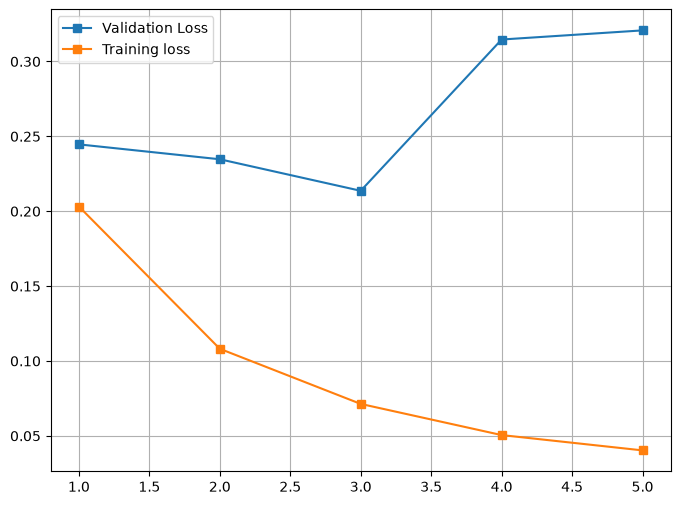

In [ ]:
import matplotlib.pyplot as plt 
import numpy as np

plt.figure(figsize=(8,6))
x= np.arange(num_epoch)+1
plt.plot(x,val_loss_curve, label = "Validation Loss" , marker = "s")
plt.plot(x,train_loss_curve , label = "Training loss", marker = "s")
plt.legend()
plt.grid()
plt.show()

In [50]:
best_model = BertForSequenceClassification.from_pretrained("google-bert/bert-base-uncased",
                                                     num_labels= 2)
path = "checkpoints/best_model.pt"

checkpoint = torch.load(path, weights_only=True)
best_model.load_state_dict(checkpoint['model_state_dict'])

best_model.to(device)
best_model.eval()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10018.68it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

## Testing the model 



In [51]:
    # ================= VALIDATION =================
print("------------------------------------------------------------------")
print("Testing")

best_model.eval()
all_predictions = []
all_labels = []
    
with torch.no_grad():

    for batch in tqdm(test_dataloader):

            batch = {key: value.to(device) for key, value in batch.items()}

            # Forward propagation only
            outputs = best_model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                token_type_ids=batch["token_type_ids"]
                
            )
            # Convert logits into predicted classes
            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(batch["labels"].cpu().tolist())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print(f"Accuracy:  {accuracy:.4f}")

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print(classification_report(
        all_labels,
        all_predictions,
        target_names=["Negative", "Positive"]
    ))

print(confusion_matrix(all_labels, all_predictions))

------------------------------------------------------------------
Testing


100%|██████████| 114/114 [00:09<00:00, 12.62it/s]


Accuracy:  0.9347
Precision: 0.9341
Recall:    0.9351
F1-score:  0.9346
              precision    recall  f1-score   support

    Negative       0.94      0.93      0.93       912
    Positive       0.93      0.94      0.93       909

    accuracy                           0.93      1821
   macro avg       0.93      0.93      0.93      1821
weighted avg       0.93      0.93      0.93      1821

[[852  60]
 [ 59 850]]


# TF-IDF Approach

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [37]:
# The test set (SetFit) names its column "text"; train/val (stanfordnlp) use "sentence". Unify.
df_test = df_test.rename(columns={"text": "sentence"})

X_train, y_train = df["sentence"], df["label"]
X_val,   y_val   = df_val["sentence"], df_val["label"]
X_test,  y_test  = df_test["sentence"], df_test["label"]


### TF-IDF dictionary
Vocabulary and IDF are learned **on the training set only** (no leakage into val/test).
`idf(t) = ln((1+N)/(1+df(t))) + 1`, `tfidf(t,d) = tf(t,d) · idf(t)`, each document L2-normalised.
Tokens are lowercase words/contractions plus `!` and `?`; unigrams + bigrams so that things like *not good* are captured.

In [33]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=r"(?u)\b\w[\w']*\b|[!?]",
    ngram_range=(1, 2),
    min_df=2,            # drop tokens seen in fewer than 2 training texts
    sublinear_tf=True,   # tf -> 1 + ln(tf)
)
Xtr = vectorizer.fit_transform(X_train)
Xva = vectorizer.transform(X_val)
Xte = vectorizer.transform(X_test)
print("TF-IDF matrix:", Xtr.shape, "| vocabulary size:", len(vectorizer.vocabulary_))

TF-IDF matrix: (67349, 74605) | vocabulary size: 74605


In [34]:
results = []
for C in [0.1, 0.3, 1, 3, 10, 30]:
    clf = LogisticRegression(C=C, max_iter=2000, solver="liblinear")
    clf.fit(Xtr, y_train)
    results.append((C, accuracy_score(y_val, clf.predict(Xva))))
    print(f"C={C:<5} val acc = {results[-1][1]:.4f}")

best_C = max(results, key=lambda r: r[1])[0]
clf = LogisticRegression(C=best_C, max_iter=2000, solver="liblinear").fit(Xtr, y_train)
print("\nBest C:", best_C)

C=0.1   val acc = 0.7844
C=0.3   val acc = 0.8131
C=1     val acc = 0.8154
C=3     val acc = 0.8234
C=10    val acc = 0.8222
C=30    val acc = 0.8280

Best C: 30


In [35]:
def evaluate(name, X, y):
    pred = clf.predict(X)
    print(f"===== {name} =====")
    print(f"Accuracy:  {accuracy_score(y, pred):.4f}")
    print(f"Precision: {precision_score(y, pred):.4f}")
    print(f"Recall:    {recall_score(y, pred):.4f}")
    print(f"F1-score:  {f1_score(y, pred):.4f}")
    print(classification_report(y, pred, target_names=["Negative", "Positive"]))
    print(confusion_matrix(y, pred), "\n")
    return pred


test_pred = evaluate("TEST", Xte, y_test)

===== TEST =====
Accuracy:  0.8336
Precision: 0.8086
Recall:    0.8735
F1-score:  0.8398
              precision    recall  f1-score   support

    Negative       0.86      0.79      0.83       912
    Positive       0.81      0.87      0.84       909

    accuracy                           0.83      1821
   macro avg       0.84      0.83      0.83      1821
weighted avg       0.84      0.83      0.83      1821

[[724 188]
 [115 794]] 



# Model Usage

In [ ]:
text = "I love NLP  "


def doc_tfidf(text, vectorizer):
    """TF-IDF dictionary for ONE text: {token: tfidf weight}."""
    vocab = vectorizer.get_feature_names_out()
    idf = vectorizer.idf_
    row = vectorizer.transform([text])
    return {vocab[j]: round(float(v), 4) for j, v in zip(row.indices, row.data)}

def predict_text(text, model , vectorizer):
    row = vectorizer.transform([text])
    output = model.predict(row)
    if output == 0 :
        prediction = "Negatif"
    else: prediction = "Positif" 
    return prediction



print("The Input text is ", predict_text(text, clf , vectorizer))

The Input text is  Positif


In [78]:
text = "i love NLP "

def Bert_sentiment_predict(model ,text,tokenizer):
    #toknize the input text 
    input_tokens= tokenizer(text,
                padding=True,
                truncation=True,
                max_length=512,
                return_tensors ='pt')
    input_tokens = {key : value.to(device)for key, value in input_tokens.items()}
    logits=model(input_ids =input_tokens['input_ids'],
                 attention_mask=input_tokens['attention_mask'],
                 token_type_ids=input_tokens['token_type_ids']
                 ).logits
    if torch.argmax(logits) == 0 :
        prediction = "Negatif"
    else : prediction = "Positif"
    return prediction
print(f"The Input text is {Bert_sentiment_predict(best_model ,text,tokenizer)}")

The Input text is Positif
